# 05.P · Solution: a tuned, explained churn model

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/cloudops-one/training-ai-ml/blob/main/modules/05-powerful-models/project/solution.ipynb)

One complete answer to the [brief](README.md). Your numbers should match where the code is the same; where you made different choices, compare the reasoning, not just the score.

## 0. Setup: the churn table from Module 03

In [1]:
import os, logging
os.environ["PYTHONWARNINGS"] = "ignore"
import optuna; optuna.logging.set_verbosity(optuna.logging.WARNING)

# --- data helper: works locally and on Colab -------------------------------
from pathlib import Path
import urllib.request

def data_path(name):
    """Return a local path to data/<name>, downloading from GitHub on Colab."""
    for parent in [Path.cwd(), *Path.cwd().parents]:
        candidate = parent / "data" / name
        if candidate.exists():
            return candidate
    url = f"https://raw.githubusercontent.com/cloudops-one/training-ai-ml/main/data/{name}"
    dest = Path(name)
    if not dest.exists():
        urllib.request.urlretrieve(url, dest)
    return dest

import pandas as pd, numpy as np
import matplotlib.pyplot as plt
import warnings; warnings.filterwarnings("ignore")

import sys
sys.path.insert(0, str(data_path("download.py").parent))
from download import load_retail
from sklearn.model_selection import train_test_split

raw = load_retail("Year 2010-2011")
sales = raw[~raw["Invoice"].astype(str).str.startswith("C")]
sales = sales[(sales["Quantity"] > 0) & (sales["Price"] > 0)].dropna(subset=["Customer ID"]).drop_duplicates()
sales = sales.assign(Revenue=sales["Quantity"] * sales["Price"])

cutoff = pd.Timestamp("2011-09-01")                       # features before, target after
past = sales[sales["InvoiceDate"] < cutoff]
future = sales[(sales["InvoiceDate"] >= cutoff) & (sales["InvoiceDate"] < "2011-12-01")]

cust = past.groupby("Customer ID").agg(orders=("Invoice", "nunique"), spend=("Revenue", "sum"),
                                       products=("StockCode", "nunique"),
                                       first_order=("InvoiceDate", "min"), last_order=("InvoiceDate", "max"))
cust["tenure_days"] = (cutoff - cust["first_order"]).dt.days
cust["days_since_last"] = (cutoff - cust["last_order"]).dt.days
future_spend = future.groupby("Customer ID")["Revenue"].sum().reindex(cust.index).fillna(0)
cust["churned"] = (future_spend == 0).astype(int)        # 1 = did not come back
cust = cust.drop(columns=["first_order", "last_order"])

features = ["orders", "spend", "products", "tenure_days", "days_since_last"]
X_train, X_test, y_train, y_test = train_test_split(
    cust[features], cust["churned"], test_size=0.25, random_state=42, stratify=cust["churned"])
print(f"{len(cust):,} customers, churn rate {cust['churned'].mean():.1%}, "
      f"train {len(X_train):,} / test {len(X_test):,}")

def expected_cost(y, p, t, c_voucher=5, c_lost=60):
    """Voucher for everyone with p >= t; a missed churner costs c_lost."""
    y, flag = np.asarray(y), np.asarray(p) >= t
    return c_voucher * flag.sum() + c_lost * ((y == 1) & ~flag).sum()

from pathlib import Path
def models_dir():
    """<repo>/models when run inside the course repo, ./models otherwise (e.g. Colab)."""
    for p in [Path.cwd(), *Path.cwd().parents]:
        if (p / "data" / "download.py").exists():
            d = p / "models"; break
    else:
        d = Path("models")
    d.mkdir(exist_ok=True)
    return d

import lightgbm as lgb, shap, joblib, datetime, sklearn
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_val_score, cross_val_predict, RandomizedSearchCV
from sklearn.metrics import roc_auc_score
from scipy.stats import loguniform, randint
cv = StratifiedKFold(5, shuffle=True, random_state=42)

3,317 customers, churn rate 43.6%, train 2,487 / test 830


## 1. Baseline

Fit the Module 03 baseline: `StandardScaler` + `LogisticRegression` in a pipeline. Report its 5-fold CV AUC on the training set (keep the per-fold scores) and its test AUC.

In [2]:
baseline = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))
cv_base = cross_val_score(baseline, X_train, y_train, cv=cv, scoring="roc_auc")
baseline.fit(X_train, y_train)
p_base = baseline.predict_proba(X_test)[:, 1]
print(f"logistic regression: CV AUC {cv_base.mean():.3f} ± {cv_base.std():.3f}   test AUC {roc_auc_score(y_test, p_base):.3f}")

logistic regression: CV AUC 0.740 ± 0.029   test AUC 0.741


## 2. Tune a boosted model

Tune `lgb.LGBMClassifier(n_estimators=200, verbose=-1, random_state=42, n_jobs=1)` with `RandomizedSearchCV` (30 iterations, the same `cv`, `scoring="roc_auc"`) over `learning_rate` (log-uniform 0.005–0.3), `num_leaves` (2–63), `min_child_samples` (5–99) and `subsample`/`colsample_bytree` (0.5–1.0, set `subsample_freq=1`). Report the best settings and CV AUC. Do not touch the test set.

In [3]:
space = {"learning_rate": loguniform(0.005, 0.3), "num_leaves": randint(2, 64),
         "min_child_samples": randint(5, 100), "subsample": [0.5, 0.7, 0.85, 1.0],
         "colsample_bytree": [0.5, 0.7, 0.85, 1.0]}
gbm_base = lgb.LGBMClassifier(n_estimators=200, subsample_freq=1, verbose=-1, random_state=42, n_jobs=1)
search = RandomizedSearchCV(gbm_base, space, n_iter=30, cv=cv, scoring="roc_auc",
                            random_state=42, n_jobs=-1).fit(X_train, y_train)
gbm = search.best_estimator_
print("best:", {k: round(v, 3) if isinstance(v, float) else v for k, v in search.best_params_.items()})
print(f"tuned LightGBM: CV AUC {search.best_score_:.3f}")

best: {'colsample_bytree': 0.7, 'learning_rate': np.float64(0.017), 'min_child_samples': 57, 'num_leaves': 3, 'subsample': 1.0}
tuned LightGBM: CV AUC 0.743


## 3. Is the difference real?

Compute the tuned model's per-fold CV AUC on the **same folds** as the baseline. Show the five fold-by-fold differences, their mean and std. Is the gain larger than the noise? Then open the test set once for both models.

In [4]:
cv_gbm = cross_val_score(gbm, X_train, y_train, cv=cv, scoring="roc_auc")
diff = cv_gbm - cv_base
print("fold differences (LightGBM − logistic):", diff.round(3))
print(f"mean {diff.mean():+.3f}, std {diff.std():.3f}")
p_gbm = gbm.predict_proba(X_test)[:, 1]
print(f"test AUC: logistic {roc_auc_score(y_test, p_base):.3f}   LightGBM {roc_auc_score(y_test, p_gbm):.3f}")

fold differences (LightGBM − logistic): [0.005 0.003 0.001 0.005 0.002]
mean +0.003, std 0.002
test AUC: logistic 0.741   LightGBM 0.742


Comparing fold by fold on the **same folds** is sharper than comparing two averages: it removes the "this fold was hard for everyone" noise. Here LightGBM wins on every fold, so the gain is consistent, but it averages only about +0.003 AUC, and the test-set difference is about 0.001. Real, and tiny.

## 4. Threshold by voucher cost

For both models, choose the cheapest threshold (£5 voucher, £60 lost customer) using cross-validated **training** predictions over thresholds 0.05–0.95. Then report the test cost of each model at its threshold, plus 'voucher to everyone' and 'voucher to nobody'.

In [5]:
grid_t = np.round(np.arange(0.05, 0.96, 0.01), 2)
def best_threshold(model):
    p_cv = cross_val_predict(model, X_train, y_train, cv=cv, method="predict_proba")[:, 1]
    return float(grid_t[int(np.argmin([expected_cost(y_train, p_cv, t) for t in grid_t]))])
t_base, t_gbm = best_threshold(baseline), best_threshold(gbm)
costs = pd.Series({f"logistic (t={t_base})": expected_cost(y_test, p_base, t_base),
                   f"LightGBM (t={t_gbm})": expected_cost(y_test, p_gbm, t_gbm),
                   "voucher to everyone": expected_cost(y_test, p_base, 0.0),
                   "voucher to nobody": expected_cost(y_test, p_base, 1.01)}, name="test cost £")
costs

logistic (t=0.07)       3945
LightGBM (t=0.09)       3905
voucher to everyone     4150
voucher to nobody      21720
Name: test cost £, dtype: int64

Both thresholds sit near the theoretical break-even £5 / £60 = 0.083. LightGBM saves about £40 on 830 customers, a rounding error next to the £17,000+ either model saves over doing nothing. The real decision is "send vouchers to almost everyone except the clearly safe", and both models make it.

## 5. Explain the model globally

Use `shap.TreeExplainer` on the tuned LightGBM. Draw the beeswarm for the test set and print mean |SHAP| per feature. Write two sentences on what drives churn risk.

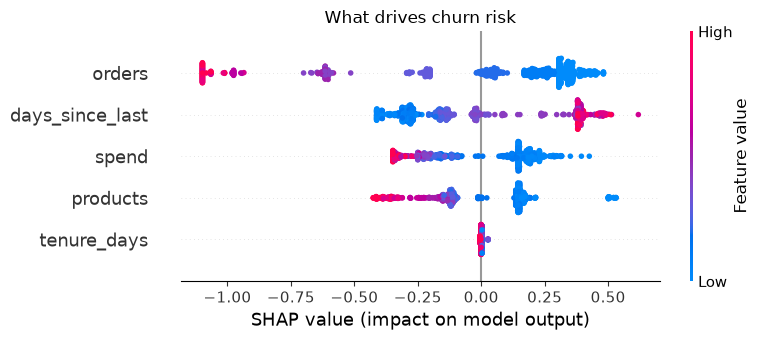

orders             0.382
days_since_last    0.282
spend              0.199
products           0.175
tenure_days        0.002
dtype: float64

In [6]:
sv = shap.TreeExplainer(gbm)(X_test)
shap.plots.beeswarm(sv, show=False); plt.title("What drives churn risk"); plt.tight_layout(); plt.show()
mean_abs = pd.Series(np.abs(sv.values).mean(axis=0), index=features).sort_values(ascending=False)
mean_abs.round(3)

## 6. Explain one customer

Pick a test customer whose LightGBM probability is close to the 75th percentile (a 'worried but not lost' customer). Draw their waterfall and print a three-line plain-English explanation: average risk, their risk, top three reasons.

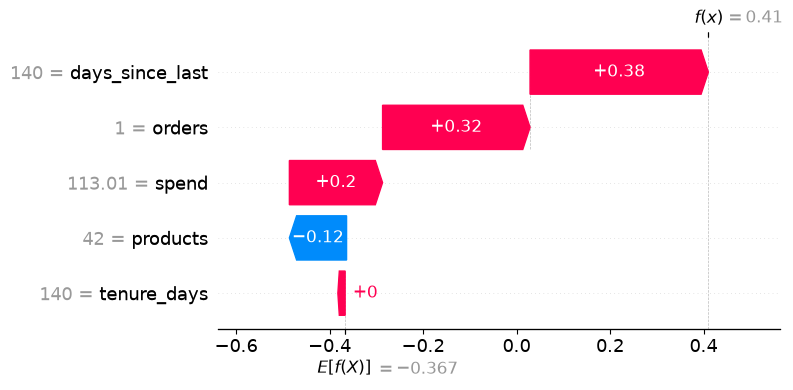

Customer 13544: average churn risk 41%, this customer 60%.
  - days_since_last = 140 raises the risk
  - orders = 1 raises the risk
  - spend = 113 raises the risk


In [7]:
q75 = np.quantile(p_gbm, 0.75)
i = int(np.abs(p_gbm - q75).argmin())
cid = X_test.index[i]
shap.plots.waterfall(sv[i], show=False); plt.tight_layout(); plt.show()
base_p = 1 / (1 + np.exp(-sv.base_values[i]))
contrib = pd.Series(sv.values[i], index=features).sort_values(key=abs, ascending=False)
print(f"Customer {int(cid)}: average churn risk {base_p:.0%}, this customer {p_gbm[i]:.0%}.")
for f in contrib.index[:3]:
    print(f"  - {f} = {X_test.iloc[i][f]:,.0f} {'raises' if contrib[f] > 0 else 'lowers'} the risk")

## 7. Choose, save, document

Apply the one-standard-error rule (05.10) to the two models' CV scores and pick the final model. Save a bundle (pipeline, features, threshold, metrics, date, versions) to `models/` with a versioned name, reload it, and score one new customer. Print a model card.

In [8]:
cv_scores = {"logistic": (cv_base.mean(), cv_base.std()), "lightgbm": (cv_gbm.mean(), cv_gbm.std())}
best_name = max(cv_scores, key=lambda k: cv_scores[k][0])
bar = cv_scores[best_name][0] - cv_scores[best_name][1]
tied = [k for k, (m, s) in cv_scores.items() if m >= bar]
chosen = "logistic" if "logistic" in tied else best_name          # simplest of the tied models
final, thr, p_final = (baseline, t_base, p_base) if chosen == "logistic" else (gbm, t_gbm, p_gbm)
print(f"best CV: {best_name} ({cv_scores[best_name][0]:.3f}); tie bar {bar:.3f}; tied: {tied}; chosen: {chosen}")

best CV: lightgbm (0.743); tie bar 0.714; tied: ['logistic', 'lightgbm']; chosen: logistic


The one-standard-error rule calls the two models tied, so the simpler one is chosen. A reasonable team could choose LightGBM for its consistent edge; what matters is that the choice is explicit and written down in the model card.

In [9]:
today = datetime.date.today().isoformat()
test_auc = roc_auc_score(y_test, p_final)
bundle = {"pipeline": final, "features": features, "threshold": thr,
          "metrics": {"cv_auc": float(cv_scores[chosen][0]), "test_auc": float(test_auc)},
          "trained_on": f"Online Retail II, orders before {cutoff.date()}", "trained": today,
          "sklearn_version": sklearn.__version__, "lightgbm_version": lgb.__version__}
path = models_dir() / f"churn_{chosen}_{today}_auc{test_auc:.3f}.joblib"
joblib.dump(bundle, path)
loaded = joblib.load(path)
new = pd.DataFrame([{"orders": 3, "spend": 520.0, "products": 25, "tenure_days": 200, "days_since_last": 120}])
p_new = loaded["pipeline"].predict_proba(new[loaded["features"]])[0, 1]
print(path.name, f"→ new customer P(churn) {p_new:.2f}, voucher: {p_new >= loaded['threshold']}")

churn_logistic_2026-10-28_auc0.741.joblib → new customer P(churn) 0.46, voucher: True


### Model card / CEO summary

In [10]:
from IPython.display import Markdown
flagged = (p_final >= thr).mean()
saving = costs["voucher to everyone"] - expected_cost(y_test, p_final, thr)
Markdown(f"""
### ShopWave churn model: one-page summary for the CEO

**What it does.** Scores every customer each month for the risk of not ordering in the next 90 days, and recommends who gets a £5 win-back voucher.

**How good is it.** It ranks customers well (AUC {test_auc:.2f} on {len(y_test)} customers it never saw). A churner is ranked above a loyal customer about {test_auc:.0%} of the time.

**Which model.** {"Logistic regression" if chosen == "logistic" else "Tuned LightGBM"}. We also tuned a gradient-boosted model (LightGBM). It scored {diff.mean():+.3f} AUC {"higher" if diff.mean() > 0 else "lower"} in cross-validation and its vouchers would cost £{costs.iloc[0] - costs.iloc[1]:,} {"less" if costs.iloc[1] < costs.iloc[0] else "more"} on the test customers. {"That gain is consistent but too small to justify a model that is harder to explain and maintain, so we chose the simpler one." if chosen == "logistic" else "That gain is large enough to justify the extra complexity."}

**What drives churn.** Few orders, a long gap since the last order, and low spend. Customers who have bought only once and not for three months or more are the highest risk.

**What we recommend.** Because a voucher (£5) is cheap compared with a lost customer (£60), send it to every customer above a {thr:.0%} risk: about {flagged:.0%} of customers. On the test customers that costs £{expected_cost(y_test, p_final, thr):,} against £{costs["voucher to everyone"]:,} for vouchers to everyone and £{costs["voucher to nobody"]:,} for doing nothing.

**Limits.** Trained on one autumn (orders before {cutoff.date()}). It cannot score brand-new customers, and it predicts who will leave, not who a voucher will win back: measure that with a randomised trial before scaling up. Retrain every quarter.
""")


### ShopWave churn model: one-page summary for the CEO

**What it does.** Scores every customer each month for the risk of not ordering in the next 90 days, and recommends who gets a £5 win-back voucher.

**How good is it.** It ranks customers well (AUC 0.74 on 830 customers it never saw). A churner is ranked above a loyal customer about 74% of the time.

**Which model.** Logistic regression. We also tuned a gradient-boosted model (LightGBM). It scored +0.003 AUC higher in cross-validation and its vouchers would cost £40 less on the test customers. That gain is consistent but too small to justify a model that is harder to explain and maintain, so we chose the simpler one.

**What drives churn.** Few orders, a long gap since the last order, and low spend. Customers who have bought only once and not for three months or more are the highest risk.

**What we recommend.** Because a voucher (£5) is cheap compared with a lost customer (£60), send it to every customer above a 7% risk: about 94% of customers. On the test customers that costs £3,945 against £4,150 for vouchers to everyone and £21,720 for doing nothing.

**Limits.** Trained on one autumn (orders before 2011-09-01). It cannot score brand-new customers, and it predicts who will leave, not who a voucher will win back: measure that with a randomised trial before scaling up. Retrain every quarter.
